# Superstore Data Analysis
**Author:** Muhammed-Raji Zainab Odunola
**Project:** 3MTT DeepTech_Ready Career Mentorship

## Objective
Explore, clean, analyze and visualize the retail transactions dataset to understand sales trends, product performance, customer purchasing behavior and the factors affecting business performance.

## About the data
- 541,909 transaction rows (1 Dec 2010 to 9 Dec 2011) with 9 columns: InvoiceNo, StockCode, Description, Quantity, InvoiceDate, UnitPrice, CustomerID, Country and Sales
- The dataset has no cost or profit column, so performance is measured using revenue (Sales)
  

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("superstoredata.csv", encoding="latin-1")

In [3]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Sales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom,20.34


In [4]:
print(df.shape)

(541909, 9)


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
 8   Sales        541909 non-null  float64
dtypes: float64(3), int64(1), object(5)
memory usage: 37.2+ MB


## 1. Data Cleaning

Before analysis, the data was checked for quality problems. Each step below was verified by comparing row counts before and after.

| Issue found | Rows affected | Action taken |
|---|---|---|
| Exact duplicate rows | 5,268 | Removed |
| Zero-price rows (including all 1,454 rows with a missing Description) | 2,512 | Removed, because they are stock adjustments and not real sales |
| Cancelled invoices (InvoiceNo starts with "C", negative Quantity) | 9,251 | Moved to a separate `returns` table |
| InvoiceDate stored as text | all rows | Converted to a datetime type |
| Missing CustomerID | 132,186 (about 25%) | Kept for revenue analysis, excluded only from customer analysis |

**Result:** 524,878 clean sales rows.

In [6]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
Sales               0
dtype: int64

In [7]:
df[df["Description"].isnull()].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Sales
622,536414,22139,NaN,56,12/1/2010 11:52,0.0,NaN,United Kingdom,0.0
1970,536545,21134,NaN,1,12/1/2010 14:32,0.0,NaN,United Kingdom,0.0
1971,536546,22145,NaN,1,12/1/2010 14:33,0.0,NaN,United Kingdom,0.0
1972,536547,37509,NaN,1,12/1/2010 14:33,0.0,NaN,United Kingdom,0.0
1987,536549,85226A,NaN,1,12/1/2010 14:34,0.0,NaN,United Kingdom,0.0
1988,536550,85044,NaN,1,12/1/2010 14:34,0.0,NaN,United Kingdom,0.0
2024,536552,20950,NaN,1,12/1/2010 14:34,0.0,NaN,United Kingdom,0.0
2025,536553,37461,NaN,3,12/1/2010 14:35,0.0,NaN,United Kingdom,0.0
2026,536554,84670,NaN,23,12/1/2010 14:35,0.0,NaN,United Kingdom,0.0
2406,536589,21777,NaN,-10,12/1/2010 16:50,0.0,NaN,United Kingdom,-0.0


In [8]:
df.duplicated().sum()

np.int64(5268)

In [9]:
print("Before:", df.shape)
df = df.drop_duplicates()
print("After:", df.shape)

Before: (541909, 9)
After: (536641, 9)


In [10]:
df = df[df["UnitPrice"] > 0]
print(df.shape)
print(df["Description"].isnull().sum())

(534129, 9)
0


In [11]:
df[df["Quantity"] < 0].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Sales
141,C536379,D,Discount,-1,12/1/2010 9:41,27.50,14527.0,United Kingdom,-27.50
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,12/1/2010 9:49,4.65,15311.0,United Kingdom,-4.65
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,12/1/2010 10:24,1.65,17548.0,United Kingdom,-19.80
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom,-6.96
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom,-6.96
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom,-6.96
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,12/1/2010 10:24,3.45,17548.0,United Kingdom,-41.40
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,12/1/2010 10:24,1.65,17548.0,United Kingdom,-19.80
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,12/1/2010 10:24,1.65,17548.0,United Kingdom,-39.60
939,C536506,22960,JAM MAKING SET WITH JARS,-6,12/1/2010 12:38,4.25,17897.0,United Kingdom,-25.50


In [12]:
df["InvoiceNo"].astype(str).str.startswith("C").sum()

np.int64(9251)

In [13]:
is_cancel = df["InvoiceNo"].astype(str).str.startswith("C")

returns = df[is_cancel]
df = df[~is_cancel]

print("Returns:", returns.shape)
print("Sales:", df.shape)

Returns: (9251, 9)
Sales: (524878, 9)


In [14]:
(df["Quantity"] < 0).sum()

np.int64(0)

In [15]:
df = df.copy()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], format="%m/%d/%Y %H:%M")
df["InvoiceDate"].dtype


dtype('<M8[ns]')

In [16]:
print(df["InvoiceDate"].min())
print(df["InvoiceDate"].max())


2010-12-01 08:26:00
2011-12-09 12:50:00


In [17]:
big_sales = df[df["Quantity"] > 10000]
big_returns = returns[returns["Quantity"] < -10000]

display(big_sales)
display(big_returns)

df = df[df["Quantity"] <= 10000]
print("Rows after removing the two fake orders:", df.shape[0])

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Sales
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom,77183.6
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom,168469.6


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Sales
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1/18/2011 10:17,1.04,12346.0,United Kingdom,-77183.6
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,12/9/2011 9:27,2.08,16446.0,United Kingdom,-168469.6


Rows after removing the two fake orders: 524876


## 2. Sales Trends

This section looks at when the business earns its revenue: by month, by day of the week and by hour of the day. December 2011 is left out of the monthly chart because the data ends on 9 December, so that month is incomplete.

**Key findings**
- **Seasonality:** monthly revenue stays between about 0.5M and 0.8M from December 2010 to August 2011, then climbs to a peak of about 1.5M in November 2011. This points to strong pre-Christmas demand.
- **Day of week:** Thursday (2.20M) and Tuesday (2.10M) together bring in about 41% of revenue. Friday (1.67M) is the weakest weekday and Sunday (0.81M) is the lowest overall. No transactions are recorded on Saturdays.
- **Time of day:** revenue builds from about 08:00, peaks between roughly 10:00 and 15:00, and drops sharply after 16:00.

**Recommendation:** build stock and run promotions ahead of October and November, and schedule campaigns and customer support around mid-week and late morning to early afternoon.

In [18]:
df["YearMonth"] = df["InvoiceDate"].dt.to_period("M")
df["Month"] = df["InvoiceDate"].dt.month_name()
df["DayName"] = df["InvoiceDate"].dt.day_name()
df["Hour"] = df["InvoiceDate"].dt.hour

df[["InvoiceDate", "YearMonth", "Month", "DayName", "Hour"]].head()

,InvoiceDate,YearMonth,Month,DayName,Hour
0,2010-12-01 08:26:00,2010-12,December,Wednesday,8
1,2010-12-01 08:26:00,2010-12,December,Wednesday,8
2,2010-12-01 08:26:00,2010-12,December,Wednesday,8
3,2010-12-01 08:26:00,2010-12,December,Wednesday,8
4,2010-12-01 08:26:00,2010-12,December,Wednesday,8


In [19]:
monthly_sales = df.groupby("YearMonth")["Sales"].sum()
monthly_sales

YearMonth
2010-12     821452.730
2011-01     612628.010
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     757841.380
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     469320.730
Freq: M, Name: Sales, dtype: float64

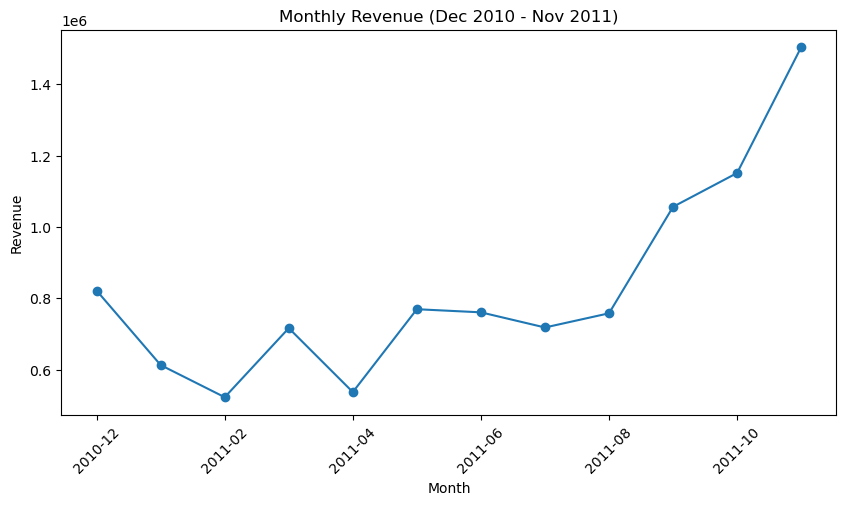

In [20]:
monthly_full = monthly_sales[:-1].copy()
monthly_full.index = monthly_full.index.astype(str)

plt.figure(figsize=(10, 5))
monthly_full.plot(kind="line", marker="o")
plt.title("Monthly Revenue (Dec 2010 - Nov 2011)")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.show()

In [21]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

daily_sales = df.groupby("DayName")["Sales"].sum().reindex(day_order)
daily_sales

DayName
Monday       1775782.071
Tuesday      2098516.911
Wednesday    1847074.380
Thursday     2199292.570
Friday       1669000.891
Saturday             NaN
Sunday        806790.781
Name: Sales, dtype: float64

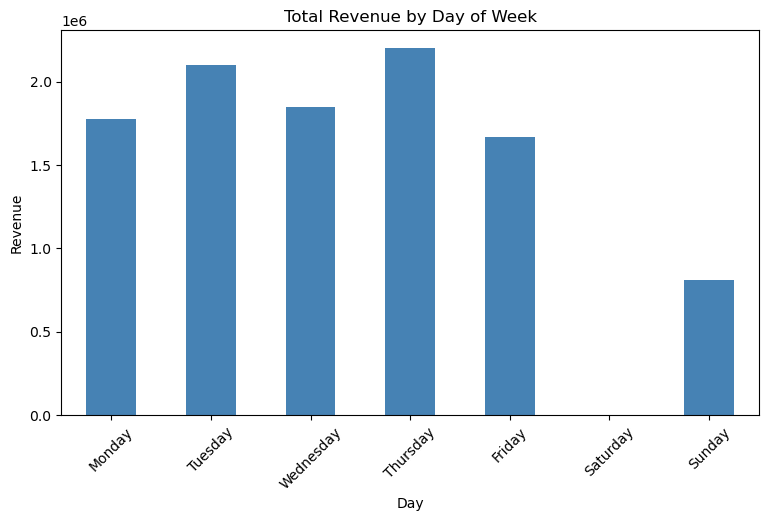

In [22]:
plt.figure(figsize=(9, 5))
daily_sales.plot(kind="bar", color="steelblue")
plt.title("Total Revenue by Day of Week")
plt.xlabel("Day")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.show()

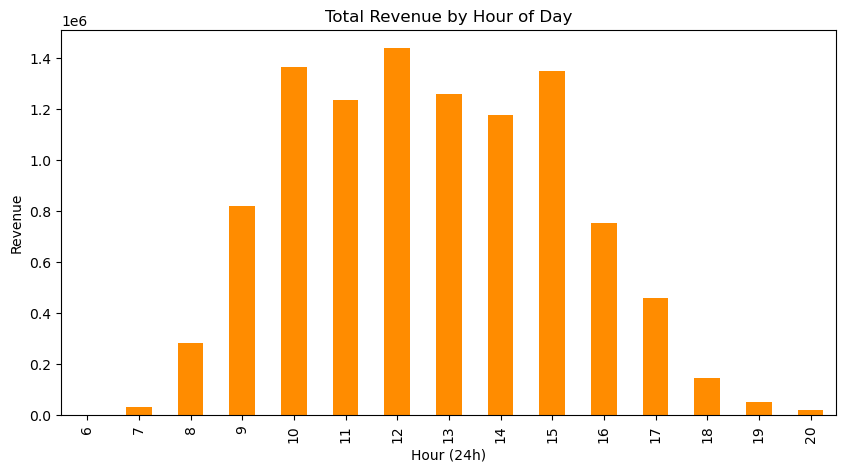

In [23]:
hourly_sales = df.groupby("Hour")["Sales"].sum()

plt.figure(figsize=(10, 5))
hourly_sales.plot(kind="bar", color="darkorange")
plt.title("Total Revenue by Hour of Day")
plt.xlabel("Hour (24h)")
plt.ylabel("Revenue")
plt.show()

## 3. Product Performance

Products were ranked by revenue, by units sold, and by the lowest earners. Two data quality problems had to be handled first.

**Data quality notes**
- **Non-product entries:** postage, carriage, manual entries, bank charges, samples and gift vouchers appear in the Description column. They are real money, so they stay in the revenue totals above, but they are excluded from product rankings (stored in `products_df`).
- **Two fake orders:** two huge orders were placed and cancelled within about 15 minutes, with the same quantity, customer and price: 80,995 units of *Paper Craft, Little Birdie* (168,470) on 9 Dec 2011, and 74,215 units of *Medium Ceramic Top Storage Jar* (77,184) on 18 Jan 2011. They are almost certainly entry errors, so they were removed. Left in, they would have ranked #2 and #7 in the revenue top 10.

**Key findings**
- **Top by revenue:** Regency Cakestand 3 Tier (about 174k), White Hanging Heart T-Light Holder (about 106k), Party Bunting (about 99k) and Jumbo Bag Red Retrospot (about 94k).
- **Top by volume:** World War 2 Gliders (54,951 units), Jumbo Bag Red Retrospot (48,371) and White Hanging Heart T-Light Holder (37,872).
- **Leaders on both lists:** Jumbo Bag Red Retrospot, White Hanging Heart T-Light Holder, Assorted Colour Bird Ornament and Rabbit Night Light.
- **Differences between the rankings:** the Regency Cakestand earns the most without being a top seller by units, while the World War 2 Gliders sell the most units without ranking in the revenue top 10. This suggests a mix of higher-priced items and high-volume, low-priced items (average price was not checked).
- **Underperformers:** 899 of 4,013 products (22.4%) earned under 100 over the year. Together they bring in 32,930, only 0.33% of product revenue. The lowest-revenue products are mostly cheap items such as cards, cake cases and charms.

**Recommendation:** protect stock of the four products that lead on both revenue and volume, and bundle, discount or drop the low earners, since removing them would barely affect revenue.

In [24]:
df[df["StockCode"].str.contains("^[A-Za-z]", regex=True)]["Description"].value_counts().head(15)

Description
POSTAGE                                1126
DOTCOM POSTAGE                          706
Manual                                  317
CARRIAGE                                141
GIRLS PARTY BAG                          13
Bank Charges                             12
BOYS PARTY BAG                           11
Dotcomgiftshop Gift Voucher Â20.00       9
Dotcomgiftshop Gift Voucher Â10.00       8
Dotcomgiftshop Gift Voucher Â30.00       7
BOXED GLASS ASHTRAY                       4
Dotcomgiftshop Gift Voucher Â50.00       4
Dotcomgiftshop Gift Voucher Â40.00       3
PADS TO MATCH ALL CUSHIONS                3
SAMPLES                                   2
Name: count, dtype: int64

In [25]:
non_products = ["DOTCOM POSTAGE", "POSTAGE", "Manual"]

products_df = df[~df["Description"].isin(non_products)]

print(df.shape)
print(products_df.shape)

(524876, 13)
(522727, 13)


In [26]:
top_products = products_df.groupby("Description")["Sales"].sum().sort_values(ascending=False).head(10)
top_products

Description
REGENCY CAKESTAND 3 TIER              174156.54
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
RABBIT NIGHT LIGHT                     66870.03
PAPER CHAIN KIT 50'S CHRISTMAS         64875.59
ASSORTED COLOUR BIRD ORNAMENT          58927.62
CHILLI LIGHTS                          54096.36
SPOTTY BUNTING                         42513.48
JUMBO BAG PINK POLKADOT                42401.01
Name: Sales, dtype: float64

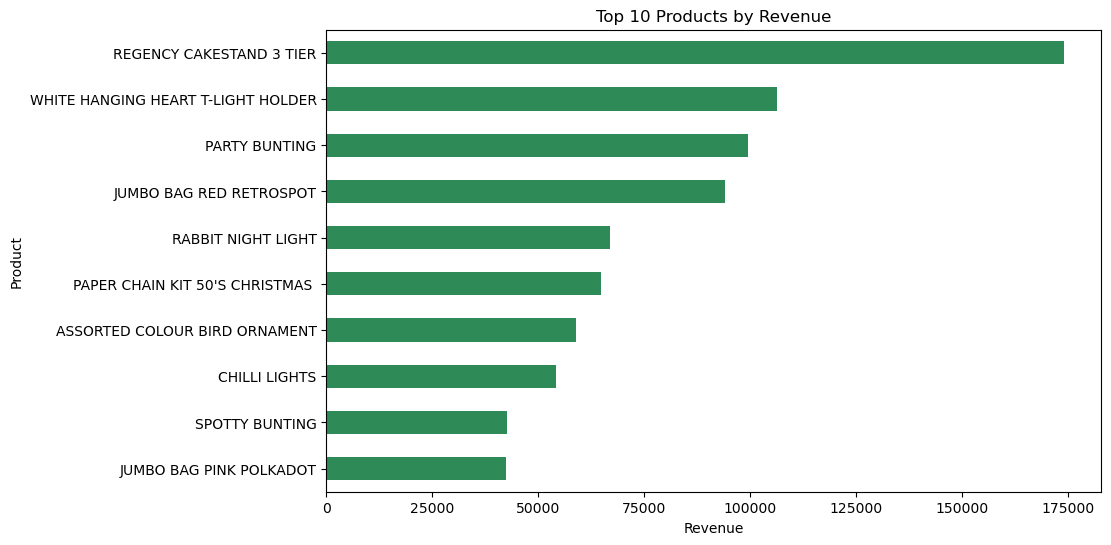

In [27]:
plt.figure(figsize=(10, 6))
top_products.sort_values().plot(kind="barh", color="seagreen")
plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")
plt.show()

In [28]:
print("Before:", df.shape)
df = df[df["Quantity"] <= 10000]
print("After:", df.shape)

products_df = df[~df["Description"].isin(non_products)]
products_df = products_df[~products_df["Description"].str.contains("Gift Voucher", case=False)]
print("Products table:", products_df.shape)

df["Quantity"].max()

Before: (524876, 13)
After: (524876, 13)
Products table: (522695, 13)


4800

In [29]:
monthly_sales = df.groupby("YearMonth")["Sales"].sum()
daily_sales = df.groupby("DayName")["Sales"].sum().reindex(day_order)
hourly_sales = df.groupby("Hour")["Sales"].sum()
top_products = products_df.groupby("Description")["Sales"].sum().sort_values(ascending=False).head(10)

print(daily_sales)
print(top_products)

DayName
Monday       1775782.071
Tuesday      2098516.911
Wednesday    1847074.380
Thursday     2199292.570
Friday       1669000.891
Saturday             NaN
Sunday        806790.781
Name: Sales, dtype: float64
Description
REGENCY CAKESTAND 3 TIER              174156.54
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
RABBIT NIGHT LIGHT                     66870.03
PAPER CHAIN KIT 50'S CHRISTMAS         64875.59
ASSORTED COLOUR BIRD ORNAMENT          58927.62
CHILLI LIGHTS                          54096.36
SPOTTY BUNTING                         42513.48
JUMBO BAG PINK POLKADOT                42401.01
Name: Sales, dtype: float64


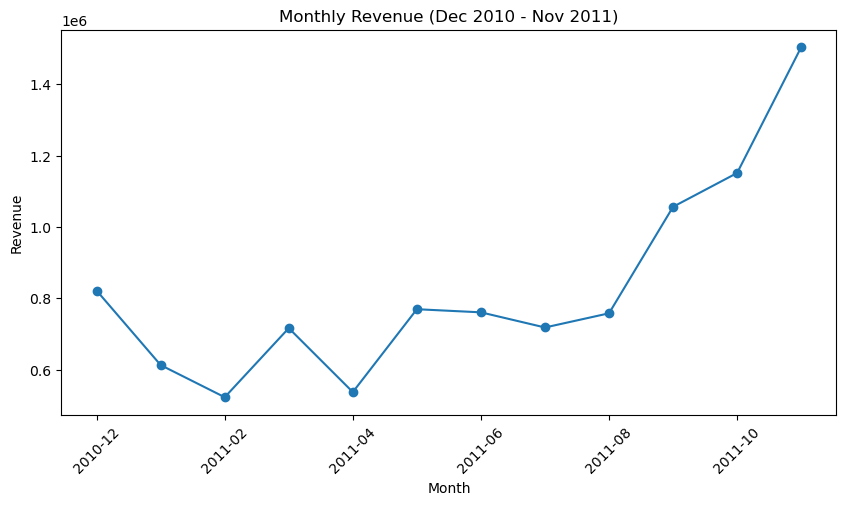

In [30]:
monthly_full = monthly_sales[:-1].copy()
monthly_full.index = monthly_full.index.astype(str)

plt.figure(figsize=(10, 5))
monthly_full.plot(kind="line", marker="o")
plt.title("Monthly Revenue (Dec 2010 - Nov 2011)")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.show()

## 4. Customer Behaviour

About 25% of rows (132,186) have no CustomerID. They are real sales, so they stay in the revenue analysis above, but customer analysis needs to know who bought. This section therefore uses only the rows with a customer ID (392,690 rows, **4,337 unique customers**).

**Key findings**
- **Revenue concentration:** the top 10 customers (0.23% of customers) bring in **16.5%** of revenue from identified customers. The largest, customer 14646, spent about 280k, and the 10th spent about 65k. Spending at this level suggests wholesale-type buyers.
- **Loyalty:** 2,844 customers (**65.6%**) ordered more than once and 1,493 (**34.4%**) ordered only once.
- **Order frequency:** the typical customer (median) placed only **2 orders** in the year. The mean is 4.3 because a few very frequent buyers pull it up, with one customer placing 209 orders.
- **Order value:** the median order is worth about **303** and the mean is about **466**, so a small number of large orders raise the average.

**Limitation:** these figures cover identified customers only, so the top 10 share of total revenue is lower than 16.5%.

**Recommendations:** look after the top accounts with dedicated service and loyalty offers, since losing a few would noticeably reduce revenue. Send a follow-up offer after a first purchase to turn one-time buyers into repeat buyers. Set free-shipping or bundle thresholds just above the median order value (about 303) to lift the value of ordinary orders.

In [31]:
customers_df = df.dropna(subset=["CustomerID"]).copy()
customers_df["CustomerID"] = customers_df["CustomerID"].astype(int)

print(df.shape)
print(customers_df.shape)

(524876, 13)
(392690, 13)


In [32]:
customers_df["CustomerID"].nunique()

4337

In [33]:
top_customers = customers_df.groupby("CustomerID")["Sales"].sum().sort_values(ascending=False).head(10)
top_customers

CustomerID
14646    280206.02
18102    259657.30
17450    194390.79
14911    143711.17
12415    124914.53
14156    117210.08
17511     91062.38
16029     80850.84
16684     66653.56
14096     65164.79
Name: Sales, dtype: float64

In [34]:
total_customer_revenue = customers_df["Sales"].sum()
top10_share = top_customers.sum() / total_customer_revenue * 100
print(round(top10_share, 1))

16.5


In [35]:
orders_per_customer = customers_df.groupby("CustomerID")["InvoiceNo"].nunique()
orders_per_customer.describe()

count    4337.000000
mean        4.272539
std         7.698808
min         1.000000
25%         1.000000
50%         2.000000
75%         5.000000
max       209.000000
Name: InvoiceNo, dtype: float64

In [36]:
one_time = (orders_per_customer == 1).sum()
repeat = (orders_per_customer > 1).sum()

print("One-time:", one_time)
print("Repeat:", repeat)
print("Repeat rate:", round(repeat / len(orders_per_customer) * 100, 1), "%")

One-time: 1493
Repeat: 2844
Repeat rate: 65.6 %


In [37]:
order_values = customers_df.groupby("InvoiceNo")["Sales"].sum()
print("Mean:", round(order_values.mean(), 2))
print("Median:", round(order_values.median(), 2))

Mean: 466.35
Median: 302.57


## 5. Performance by Country

Revenue was totalled by country using all clean sales rows, including those without a CustomerID, because shipping to a country counts as revenue either way. Because the United Kingdom is so large, the chart below excludes it so the other markets can be compared.

**Key findings**
- **UK dependence:** the United Kingdom generates about 8.76M, which is **84.2%** of revenue.
- **Main export markets:** the Netherlands (285k, 2.7%), EIRE/Ireland (283k, 2.7%), Germany (229k, 2.2%), France (210k, 2.0%) and Australia (138k, 1.3%). Together they make up about 11% of revenue.
- **Two tiers outside the UK:** the five markets above are each over 138k, while all other countries are below 62k.

**Recommendation:** the heavy reliance on one market is a risk. Test targeted campaigns in the Netherlands, Germany and France, which have the strongest base outside the UK, before investing in the smaller markets.

In [38]:
country_sales = df.groupby("Country")["Sales"].sum().sort_values(ascending=False)
country_share = (country_sales / country_sales.sum() * 100).round(1)

print(country_sales.head(10))
print(country_share.head(10))

Country
United Kingdom    8756090.894
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: Sales, dtype: float64
Country
United Kingdom    84.2
Netherlands        2.7
EIRE               2.7
Germany            2.2
France             2.0
Australia          1.3
Spain              0.6
Switzerland        0.5
Belgium            0.4
Sweden             0.4
Name: Sales, dtype: float64


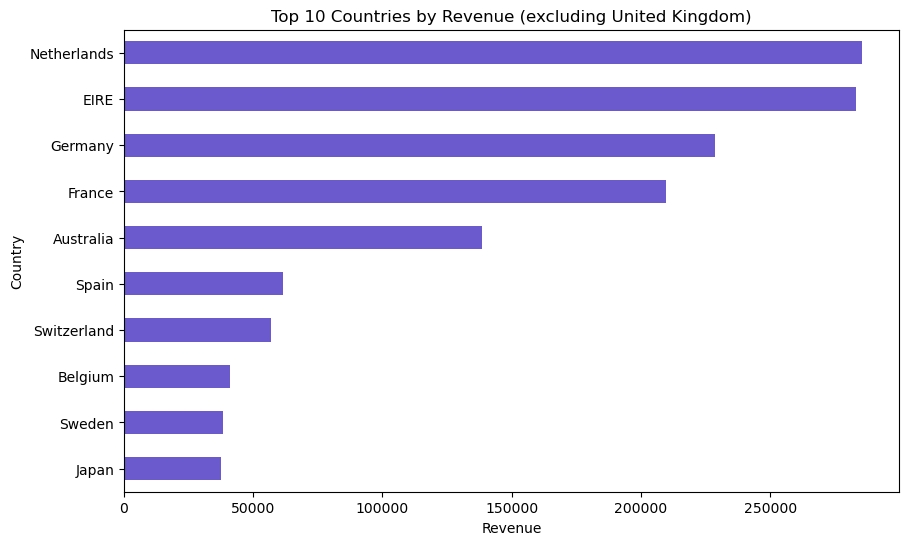

In [39]:
non_uk = country_sales.drop("United Kingdom").head(10)

plt.figure(figsize=(10, 6))
non_uk.sort_values().plot(kind="barh", color="slateblue")
plt.title("Top 10 Countries by Revenue (excluding United Kingdom)")
plt.xlabel("Revenue")
plt.ylabel("Country")
plt.show()

In [40]:
top_quantity = products_df.groupby("Description")["Quantity"].sum().sort_values(ascending=False).head(10)
top_quantity

Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
PACK OF 12 LONDON TISSUES             26119
PACK OF 60 PINK PAISLEY CAKE CASES    24820
Name: Quantity, dtype: int64

In [41]:
bottom_products = products_df.groupby("Description")["Sales"].sum().sort_values().head(10)
bottom_products

Description
PADS TO MATCH ALL CUSHIONS             0.003
HEN HOUSE W CHICK IN NEST              0.420
SET 12 COLOURING PENCILS DOILEY        0.650
VINTAGE BLUE TINSEL REEL               0.840
PINK CRYSTAL GUITAR PHONE CHARM        0.850
CAT WITH SUNGLASSES BLANK CARD         0.950
HAPPY BIRTHDAY CARD TEDDY/CAKE         0.950
60 GOLD AND SILVER FAIRY CAKE CASES    1.100
PACK 4 FLOWER/BUTTERFLY PATCHES        1.250
ETCHED GLASS STAR TREE DECORATION      1.250
Name: Sales, dtype: float64

In [42]:
product_revenue = products_df.groupby("Description")["Sales"].sum()

print("Total products:", len(product_revenue))
print("Earned under 100:", (product_revenue < 100).sum())

Total products: 4016
Earned under 100: 900


In [43]:
low_revenue = product_revenue[product_revenue < 100].sum()
total_revenue = product_revenue.sum()

print("Revenue from low earners:", round(low_revenue, 2))
print("Share of product revenue:", round(low_revenue / total_revenue * 100, 2), "%")

Revenue from low earners: 32993.34
Share of product revenue: 0.33 %


## 6. Summary and Recommendations

**Overview:** after cleaning, the analysis covers 524,878 sales rows from 1 December 2010 to 9 December 2011. Revenue is highly seasonal, concentrated in the UK and a small group of products and customers, and held back by a long tail of low-earning products.

**Main findings**
1. **Seasonality:** revenue peaks at about 1.5M in November 2011, roughly double the February to August level.
2. **Timing:** Tuesday and Thursday bring in about 41% of revenue, and sales peak between 10:00 and 15:00.
3. **Products:** four products lead on both revenue and volume. 22.4% of products earn under 100 and make up only 0.33% of product revenue.
4. **Customers:** 65.6% of customers are repeat buyers, but the typical customer orders only twice. The top 10 customers bring in 16.5% of identified-customer revenue.
5. **Markets:** the UK makes up 84.2% of revenue. The Netherlands, EIRE, Germany, France and Australia are the main export markets.

**Recommendations**
1. Build stock and run promotions ahead of October and November.
2. Schedule marketing and customer support for mid-week and late morning to early afternoon.
3. Protect stock of the best sellers, and bundle, discount or drop the low earners.
4. Look after the top customers, and convert one-time buyers with follow-up offers.
5. Reduce UK dependence by testing campaigns in the Netherlands, Germany and France.

**Limitations**
- The dataset has no cost or profit column, so performance is measured by revenue, not profit.
- About 25% of rows have no CustomerID, so customer findings cover identified customers only.
- December 2011 is incomplete, and no Saturday transactions are recorded.
- Two orders that were placed and cancelled within minutes were removed as entry errors.